# BumbaLM - Exploracao e Geracao de Pares Juridicos

### Estrutura do Notebook:
1. **Setup e Parametros**: Definicao do caminho do `consolidado.jsonl` (ou `.parquet`), sigla do tribunal e limiares de qualidade.
2. **PARTE 1 - Exploracao e Diagnostico**:
   - Inspecao do primeiro registro e tabela de presenca de chaves;
   - Diagnostico de ementa vs teor (razao de tamanho, presenca da ementa no teor, fonte do inteiro teor);
   - Visualizador formatado em HTML com caixas destacadas para leitura.
3. **PARTE 2 - Geracao de Pares em JSONL**:
   - Limpeza juridica e filtros de qualidade;
   - Gravacao em streaming mantendo consumo de RAM < 50 MB (zero risco de OOM);
   - Formato canonico do BumbaLM (`str_tribunal`, `str_numero_unico`, `str_ementa`, `str_inteiro_teor`);
   - Saida direta em texto puro `.jsonl` (pronto para inspecao no Bloco de Notas ou VS Code);
   - Amostras visuais dos pares salvos;
   - Graficos estatisticos com histogramas de palavras da ementa e do teor;
   - Filtragem opcional por contagem de palavras minimas (`pares_limpo.jsonl`).

---

In [2]:
# Bibliotecas essenciais
import html
import json
import random
import re
import time
import numpy as np
import gzip
from collections import Counter, defaultdict
from pathlib import Path
from typing import Generator, Any, Optional

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, display
from tqdm.auto import tqdm

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")

print("[OK] Bibliotecas carregadas com sucesso.")

[OK] Bibliotecas carregadas com sucesso.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Parametros Configuraveis

Preencha os campos abaixo com o caminho do seu arquivo consolidado e os parametros de corte desejados:

In [3]:
#@title Parametros do Tribunal e Regua de Qualidade
# 1. Caminho do arquivo consolidado bruto da raspagem:
CAMINHO_CONSOLIDADO = "/content/drive/MyDrive/Raspagem_Dados/TJRN/rn_consolidado.jsonl" #@param {type:"string"}
SIGLA_TRIBUNAL = "TJRN" #@param {type:"string"}

# 2. Pasta onde os pares gerados em .jsonl serao gravados:
PASTA_SAIDA = "/content/drive/MyDrive/Pares_Tribunais" #@param {type:"string"}

# 3. Parametros da Amostra para Exploracao e Simulador (Parte 1):
N_AMOSTRAS_EXPLORAR = 5000 #@param {type:"integer"}
# 200 registros fornecem uma amostragem confiavel para a curva de retencao sem lentidao.
RECORTE_VISUALIZADOR = 20000 #@param {type:"integer"}

# 4. Regua Unificada de Corte (Parte 2):
MIN_PALAVRAS_EMENTA = 50 #@param {type:"integer"}
# ~250 caracteres
MIN_PALAVRAS_TEOR = 150 #@param {type:"integer"}
# ~1.100 caracteres
FATOR_TEOR_EMENTA = 1.5 #@param {type:"number"}
# Teor deve ter pelo menos FATOR_TEOR_EMENTA * palavras_da_ementa

MAX_PARES = 0 #@param {type:"integer"}
# 0 = processa o arquivo inteiro; > 0 = limite maximo de pares para teste rapido.

# 5. Sobrescrita manual opcional de colunas (deixe vazio para auto-deteccao):
COLUNA_NUMERO_CUSTOM = "" #@param {type:"string"}
COLUNA_EMENTA_CUSTOM = "" #@param {type:"string"}
COLUNA_TEOR_CUSTOM = "" #@param {type:"string"}

Path(PASTA_SAIDA).mkdir(parents=True, exist_ok=True)

print("=" * 84)
print(f"Tribunal Alvo       : {SIGLA_TRIBUNAL}")
print(f"Arquivo de Entrada  : {CAMINHO_CONSOLIDADO}")
print(f"Pasta de Saida      : {PASTA_SAIDA}")
print(f"Formato Gerado      : .jsonl puro (texto direto)")
print(f"Filtro Ementa       : >= {MIN_PALAVRAS_EMENTA} palavras (~{MIN_PALAVRAS_EMENTA * 7} caracteres)")
print(f"Filtro Teor         : >= {MIN_PALAVRAS_TEOR} palavras (~{MIN_PALAVRAS_TEOR * 7} caracteres)")
print(f"Fator Razao Teor/Em : >= {FATOR_TEOR_EMENTA}x mais palavras no teor que na ementa")
print("=" * 84)

Tribunal Alvo       : TJRN
Arquivo de Entrada  : /content/drive/MyDrive/Raspagem_Dados/TJRN/rn_consolidado.jsonl
Pasta de Saida      : /content/drive/MyDrive/Pares_Tribunais
Formato Gerado      : .jsonl puro (texto direto)
Filtro Ementa       : >= 50 palavras (~350 caracteres)
Filtro Teor         : >= 150 palavras (~1050 caracteres)
Fator Razao Teor/Em : >= 1.5x mais palavras no teor que na ementa


## 2. Limpeza Textual

In [4]:
NUMERO_RE = re.compile(r"\D+")
HTML_RE = re.compile(r"<[^>]+>")
CARIMBOS_RE = re.compile(
    r"(?i)(?:documento\s+assinado\s+digitalmente[^\n]*|"
    r"assinado\s+eletronicamente\s+por[^\n]*|"
    r"num\.\s*\d+\s*-\s*p[aág]\.\s*\d+|"
    r"p[aág]gina\s+\d+\s+de\s+\d+)"
)

def limpar_texto(valor) -> str:
    """Limpeza de HTML, carimbos, recomposicao avancada de quebras de linha e correcao de kerning/OCR."""
    if valor is None:
        return ""
    texto = str(valor).replace("\u00a0", " ").replace("\r\n", "\n").replace("\r", "\n").strip()
    texto = html.unescape(texto)

    # Converte quebras de bloco HTML em quebras de linha antes de remover tags
    texto = re.sub(r"(?i)<\s*(?:br|p|div|tr|li|\/p|\/div|\/tr|\/li)[^>]*>", "\n", texto)
    if HTML_RE.search(texto):
        texto = HTML_RE.sub(" ", texto)
    if CARIMBOS_RE.search(texto):
        texto = CARIMBOS_RE.sub(" ", texto)

    # 1. Normaliza espacos ao redor de quebras de linha
    texto = re.sub(r"[ \t]*\n[ \t]*", "\n", texto)

    # 2. Caracteres, parenteses e operadores isolados em linha propria
    texto = re.sub(r"\n+([:;/\\–—\-])\n+", r"\1 ", texto)
    texto = re.sub(r"\(\s*([a-zA-Z0-9ivxldcmIVXLDCM§º°ª\.\-]+)\s*\)", r"(\1)", texto)
    texto = re.sub(r"(?i)\b([a-z0-9])\s*/\s*([a-z0-9])\b", r"\1/\2", texto)

    # 3. Recomposicao de linhas quebradas no meio de frases (Line Reflow / Unwrap)
    texto = re.sub(r"([a-zA-Zá-úÁ-Úà-ùÀ-Ùâ-ûÂ-Ûã-õÃ-ÕçÇ0-9,])\n+([a-zá-úà-ùâ-ûã-õç])", r"\1 \2", texto)
    texto = re.sub(r"([,;\-–—])\n+([A-ZÁ-ÚÀ-ÙÂ-ÛÃ-Õa-zá-úà-ùâ-ûã-õçÇ0-9§])", r"\1 \2", texto)
    texto = re.sub(r"(?i)\b(e\.|d\.|art\.|arts\.|inc\.|incs\.|fls?\.|lei|n[º°ª]|par[aá]grafo|c/c|c\.c\.|d[oe]|d[ao]s?)\n+([A-ZÁ-ÚÀ-ÙÂ-ÛÃ-Õa-zá-úà-ùâ-ûã-õçÇ0-9§])", r"\1 \2", texto)
    preps = "de|do|da|dos|das|em|no|na|nos|nas|com|por|para|ao|aos|sob|sobre|pelo|pela|pelos|pelas|c/c"
    texto = re.sub(rf"(?i)\b({preps})\n+([A-ZÁ-ÚÀ-ÙÂ-ÛÃ-Õ0-9§][a-zá-úà-ùâ-ûã-õç0-9]*)", r"\1 \2", texto)
    texto = re.sub(r"(\b\d+[a-zA-Zº°ª]*|\b\d+X)\n+([A-ZÁ-ÚÀ-ÙÂ-ÛÃ-Õa-zá-úà-ùâ-ûã-õçÇ0-9§])", r"\1 \2", texto)
    texto = re.sub(r"([A-ZÁ-ÚÀ-ÙÂ-ÛÃ-Õ][a-zá-úà-ùâ-ûã-õç]+)\n+([A-ZÁ-ÚÀ-ÙÂ-ÛÃ-Õ][a-zá-úà-ùâ-ûã-õç]+)", r"\1 \2", texto)
    texto = re.sub(r"(:)\n+([A-ZÁ-ÚÀ-ÙÂ-ÛÃ-Õ0-9])", r"\1 \2", texto)

    # 4. Correcao de kerning e letras soltas de extratores PDF
    texto = re.sub(r"\b([B-HJ-NP-TW-Z])\s+([a-zá-úà-ùâ-ûã-õç]{3,})\b", r"\1\2", texto)
    texto = re.sub(r"\b([b-df-hj-np-tv-z])\s+([a-zá-úà-ùâ-ûã-õç]{3,})\b", r"\1\2", texto)
    texto = re.sub(r"\b(d)\s+([oas]{1,2})\b", r"\1\2", texto)
    texto = re.sub(r"\b([a-zA-Zá-úÁ-Úà-ùÀ-Ùâ-ûÂ-Ûã-õÃ-ÕçÇ]{3,}[a-zá-úà-ùâ-ûã-õç])\s+([sS])\b(?=[^\w]|$)", r"\1s", texto)
    texto = re.sub(r"\b([a-zA-Zá-úÁ-Úà-ùÀ-Ùâ-ûÂ-Ûã-õÃ-ÕçÇ]{3,}(?:post|pel|ativ|itiv|ad|ent))\s+([oOaA])\b", r"\1\2", texto)
    texto = re.sub(r"\b([a-zA-Zá-úÁ-Úà-ùÀ-Ùâ-ûÂ-Ûã-õÃ-ÕçÇ]{4,}amen)\s+to\b", r"\1to", texto)
    texto = re.sub(r"\b([a-zA-Zá-úÁ-Úà-ùÀ-Ùâ-ûÂ-Ûã-õÃ-ÕçÇ]{4,}(?:tiv|tiva|ria|iva|ica|al|el|il))\s+mente\b", r"\1mente", texto)
    texto = re.sub(r"\b(insufici[eê]n)\s+ci\s+a\b", r"\1cia", texto)
    texto = re.sub(r"\b(redimensio)\s+na\s+(mento)\b", r"\1na\2", texto)

    # 5. Normalizacao final de espacos e paragrafos reais
    texto = re.sub(r"[ \t]+", " ", texto)
    texto = re.sub(r"\n{3,}", "\n\n", texto)
    return texto.strip()


def eh_texto_valido(texto: str, min_taxa_letras: float = 0.40, min_taxa_palavras_reais: float = 0.50) -> bool:
    """Verifica se o texto e legivel em portugues ou se e lixo de extracao de PDF (fontes CID, glifos, OCR quebrado)."""
    if not texto or not isinstance(texto, str):
        return False
    chars_total = len(texto)
    if chars_total == 0:
        return False
    letras = len(re.findall(r"[a-zA-Zá-úÁ-Úà-ùÀ-Ùâ-ûÂ-Ûã-õÃ-ÕçÇ]", texto))
    if (letras / chars_total) < min_taxa_letras:
        return False
    palavras = texto.split()
    if not palavras:
        return False
    palavras_reais = sum(1 for p in palavras if re.search(r"[a-zA-Zá-úÁ-Úà-ùÀ-Ùâ-ûÂ-Ûã-õÃ-ÕçÇ]{2,}", p))
    if (palavras_reais / len(palavras)) < min_taxa_palavras_reais:
        return False
    # Anomalia de barras de glifos de PDF (ex: /0/1 /2/0 quebrado)
    if (texto.count("/") / chars_total) > 0.08:
        return False
    return True

def iterar_registros(caminho: Path, limite: Optional[int] = None) -> Generator[dict[str, Any], None, None]:
    """Le registros em streaming continuo para .jsonl, .json, .jsonl.gz ou .parquet sem estourar memoria RAM."""
    caminho = Path(caminho)
    sufixo = caminho.suffix.lower()
    count = 0
    if sufixo == ".gz" or str(caminho).lower().endswith(".jsonl.gz"):
        with gzip.open(caminho, "rt", encoding="utf-8", errors="replace") as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                try:
                    obj = json.loads(linha)
                except Exception:
                    continue
                if isinstance(obj, dict):
                    yield obj
                    count += 1
                    if limite and count >= limite:
                        return
                elif isinstance(obj, list):
                    for item in obj:
                        if isinstance(item, dict):
                            yield item
                            count += 1
                            if limite and count >= limite:
                                return
    elif sufixo in [".jsonl", ".json"]:
        # Verifica se o arquivo comeca com '[' (array JSON monolitico gigante como no TCU)
        eh_array_json = False
        with open(caminho, "r", encoding="utf-8", errors="replace") as f_check:
            chars_iniciais = f_check.read(100).strip()
            if chars_iniciais.startswith("["):
                eh_array_json = True

        if eh_array_json:
            # Leitura em streaming por chunks pequenos (consumo < 20 MB RAM, zero risco de OOM)
            decoder = json.JSONDecoder()
            chunk_size = 2 * 1024 * 1024
            with open(caminho, "r", encoding="utf-8", errors="replace") as f:
                while True:
                    c = f.read(1)
                    if not c or c == "[":
                        break
                buf = ""
                while True:
                    if len(buf) < chunk_size // 2:
                        more = f.read(chunk_size)
                        if not more and not buf.strip():
                            break
                        buf += more
                    buf = buf.lstrip(" \t\r\n,")
                    if not buf or buf.startswith("]"):
                        break
                    try:
                        obj, end_idx = decoder.raw_decode(buf)
                        buf = buf[end_idx:]
                        if isinstance(obj, dict):
                            yield obj
                            count += 1
                            if limite and count >= limite:
                                return
                    except json.JSONDecodeError:
                        more = f.read(chunk_size)
                        if not more:
                            break
                        buf += more
        else:
            # Leitura linha a linha padrao para .jsonl
            with open(caminho, "r", encoding="utf-8", errors="replace") as f:
                for linha in f:
                    linha = linha.strip()
                    if not linha:
                        continue
                    try:
                        obj = json.loads(linha)
                    except Exception:
                        continue
                    if isinstance(obj, dict):
                        yield obj
                        count += 1
                        if limite and count >= limite:
                            return
                    elif isinstance(obj, list):
                        for item in obj:
                            if isinstance(item, dict):
                                yield item
                                count += 1
                                if limite and count >= limite:
                                    return
    elif sufixo == ".parquet":
        parquet_file = pq.ParquetFile(caminho)
        for batch in parquet_file.iter_batches(batch_size=2000):
            pydict = batch.to_pydict()
            cols = list(pydict.keys())
            n_rows = len(pydict[cols[0]]) if cols else 0
            for i in range(n_rows):
                row = {c: pydict[c][i] for c in cols}
                yield row
                count += 1
                if limite and count >= limite:
                    return
    else:
        raise ValueError(f"Formato nao suportado: {sufixo}")

def pegar_numero(rec: dict, col_custom: str = "") -> str:
    """Extrai o numero do processo com busca inteligente e tolerante entre tribunais, incluindo PROC/KEY do TCU."""
    if not isinstance(rec, dict):
        return ""
    if col_custom and col_custom in rec:
        val = rec[col_custom]
        if val and str(val).strip():
            return re.sub(r"<[^>]+>", "", str(val)).strip()

    candidatos = [
        "PROC", "proc", "KEY", "key",
        "numero_processo", "numeroProcesso", "numeroprocesso", "str_numero_unico",
        "processo", "proc", "num_processo", "numProcesso", "nro_processo", "nroProcesso",
        "nr_processo", "numero_cnj", "numeroCnj", "cnj", "numero", "key",
        "numero_registro", "num_registro", "num_documento", "cod_processo", "processo_numero"
    ]
    for c in candidatos:
        for k in [c, c.upper(), c.capitalize()]:
            val = rec.get(k)
            if val and str(val).strip():
                clean_val = re.sub(r"<[^>]+>", "", str(val)).strip()
                if clean_val and clean_val not in ["000.000/0000-0", "null", "none", "vazio"]:
                    return clean_val

    for k, v in rec.items():
        kl = k.lower()
        if ("processo" in kl or "proc" in kl or "numero" in kl) and not kl.startswith("dt_") and not kl.startswith("data_") and not "quantidade" in kl and not "caracteres" in kl:
            if v and str(v).strip():
                clean_v = re.sub(r"<[^>]+>", "", str(v)).strip()
                if clean_v and clean_v not in ["000.000/0000-0", "null", "none", "vazio"]:
                    return clean_v

    for id_k in ["_id_interno", "id_fonte", "id_jurisprudencia", "KEY", "key", "id"]:
        val = rec.get(id_k)
        if val and str(val).strip():
            return str(val).strip()

    return ""

def pegar_id(rec: dict) -> str:
    if not isinstance(rec, dict):
        return ""
    for c in ["_id_interno", "id_fonte", "id_jurisprudencia", "idJurisprudencia", "KEY", "key", "id", "id_documento", "id_processo", "uuid"]:
        val = rec.get(c)
        if val and str(val).strip():
            return str(val).strip()
    return ""

def pegar_ementa(rec: dict, col_custom: str = "") -> str:
    """Busca inteligente da ementa, suportando SUMARIO/ASSUNTO do TCU, ementa_html, textoementa, etc."""
    if not isinstance(rec, dict):
        return ""
    if col_custom and col_custom in rec:
        val = rec[col_custom]
        if val and str(val).strip():
            return re.sub(r"<[^>]+>", "", str(val)).strip()

    candidatos = [
        "SUMARIO", "sumario",
        "ementa_html", "ementa", "textoementa", "ementatextopuro", "str_ementa",
        "assunto", "resumo", "ementa_texto", "texto_ementa", "ementa_original", "dispositivo"
    ]
    melhor_texto = ""
    for c in candidatos:
        for k in [c, c.upper(), c.capitalize()]:
            val = rec.get(k)
            if not val:
                continue
            txt = re.sub(r"<[^>]+>", "", str(val)).strip()
            if txt.lower() in [
                "removido no backend", "removido", "null", "none", "vazio",
                "numero de acordao nao utilizado", "número de acórdão não utilizado"
            ]:
                continue
            if len(txt.split()) > len(melhor_texto.split()):
                melhor_texto = txt

    if len(melhor_texto.split()) >= 5:
        return melhor_texto

    for k, v in rec.items():
        kl = k.lower()
        if "ementa" in kl or "sumario" in kl or "assunto" in kl:
            txt = re.sub(r"<[^>]+>", "", str(v or "")).strip()
            if txt.lower() not in ["removido no backend", "removido", "null", "none", "vazio"]:
                if len(txt.split()) > len(melhor_texto.split()):
                    melhor_texto = txt

    return melhor_texto

def pegar_teor(rec: dict, col_custom: str = "") -> str:
    if not isinstance(rec, dict):
        return ""
    """Busca inteligente do inteiro teor, selecionando o campo mais completo e ignorando dummies como 'removido no backend'."""
    if col_custom and col_custom in rec:
        val = rec[col_custom]
        if isinstance(val, list):
            return "\n".join(str(x) for x in val if x).strip()
        return str(val or "").strip()

    candidatos = [
        "inteiro_teor_html", "inteiro_teor", "texto_inteiro_teor", "textopuro",
        "textooriginal", "inteiro_teor_rtf", "str_inteiro_teor", "teor",
        "conteudo_documento", "documento_texto"
    ]

    melhor_texto = ""
    for c in candidatos:
        val = rec.get(c)
        if val is None:
            continue
        if isinstance(val, list):
            txt = "\n".join(str(x) for x in val if x).strip()
        else:
            txt = str(val).strip()

        if txt.lower() in ["removido no backend", "removido", "nao informado", "null", "none", "vazio"]:
            continue

        if len(txt.split()) > len(melhor_texto.split()):
            melhor_texto = txt

    if len(melhor_texto.split()) >= 10:
        return melhor_texto

    for k, v in rec.items():
        kl = k.lower()
        if ("teor" in kl or "textopuro" in kl or "textooriginal" in kl) and "caracteres" not in kl and "num_" not in kl and "ementa" not in kl:
            if isinstance(v, list):
                txt = "\n".join(str(x) for x in v if x).strip()
            else:
                txt = str(v).strip()
            if txt.lower() in ["removido no backend", "removido"]:
                continue
            if len(txt.split()) > len(melhor_texto.split()):
                melhor_texto = txt

    return melhor_texto

def detectar_fonte_teor(rec: dict, col_custom: str = "") -> str:
    if not isinstance(rec, dict):
        return "(vazio)"
    if col_custom and col_custom in rec:
        return col_custom
    candidatos = [
        "inteiro_teor_html", "inteiro_teor", "texto_inteiro_teor", "textopuro",
        "textooriginal", "str_inteiro_teor", "teor"
    ]
    melhor_col = "(vazio)"
    max_len = 0
    for c in candidatos:
        val = rec.get(c)
        if val:
            txt = "\n".join(str(x) for x in val if x) if isinstance(val, list) else str(val)
            if txt.strip().lower() in ["removido no backend", "removido", "nao informado", "null", "none", "vazio"]:
                continue
            tam = len(txt.split())
            if tam > max_len:
                max_len = tam
                melhor_col = c
    return melhor_col

print("[OK] Funcoes utilitarias configuradas.")


[OK] Funcoes utilitarias configuradas.


## PARTE 1: Exploracao

In [5]:
# 1.0 Carregar amostra para analise inicial
caminho_entrada = Path(CAMINHO_CONSOLIDADO)
assert caminho_entrada.is_file(), f"[ERRO] Arquivo nao encontrado: {caminho_entrada}"

tam_gb = caminho_entrada.stat().st_size / 1e9
print("=" * 84)
print(f"ARQUIVO BRUTO : {caminho_entrada.name}")
print(f"TAMANHO TOTAL : {tam_gb:.2f} GB ({caminho_entrada.stat().st_size / 1e6:.1f} MB)")
print(f"Lendo amostra de {N_AMOSTRAS_EXPLORAR} registros para analise...")
print("=" * 84)

amostra_exploracao = list(iterar_registros(caminho_entrada, limite=N_AMOSTRAS_EXPLORAR))
assert amostra_exploracao, "Nenhum registro valido lido do arquivo."

rec0 = amostra_exploracao[0]
print(f"Chaves do registro 0: {sorted(rec0.keys())}")
print(f"numeroProcesso : {pegar_numero(rec0, COLUNA_NUMERO_CUSTOM)}")
print(f"id             : {pegar_id(rec0)}")
fonte_teor_detectada = next((detectar_fonte_teor(x, COLUNA_TEOR_CUSTOM) for x in amostra_exploracao if detectar_fonte_teor(x, COLUNA_TEOR_CUSTOM) != '(vazio)'), '(vazio)')
print(f"Fonte do Teor  : {fonte_teor_detectada}")

# Tabela de ocorrencia de chaves
contador_chaves = Counter()
for r in amostra_exploracao:
    if isinstance(r, dict):
        contador_chaves.update(r.keys())

df_chaves = pd.DataFrame([
    {"campo": k, "aparece_em": v, "taxa_pct": round(100 * v / len(amostra_exploracao), 1)}
    for k, v in sorted(contador_chaves.items(), key=lambda x: (-x[1], x[0]))
])

print("\nTABELA DE CAMPOS E PREENCHIMENTO:")
with pd.option_context("display.max_rows", None):
    display(df_chaves)


ARQUIVO BRUTO : rn_consolidado.jsonl
TAMANHO TOTAL : 6.81 GB (6813.8 MB)
Lendo amostra de 5000 registros para analise...
Chaves do registro 0: ['avisos_extracao_texto', 'classe_judicial', 'colegiado', 'dt_assinatura_ementa', 'dt_assinatura_teor', 'dt_publicacao', 'ementa', 'grau', 'id_documento_ementa', 'id_documento_teor', 'id_jurisprudencia', 'inteiro_teor', 'magistrado', 'num_documentos_inteiro_teor', 'num_documentos_inteiro_teor_extraidos', 'numero_processo', 'orgao_julgador', 'origem', 'sigiloso', 'sistema', 'texto_inteiro_teor', 'texto_inteiro_teor_caracteres', 'tipo_teor']
numeroProcesso : 08887731720258205001
id             : bilkXaABYGx659SB4BZO
Fonte do Teor  : texto_inteiro_teor

TABELA DE CAMPOS E PREENCHIMENTO:


,campo,aparece_em,taxa_pct
0,avisos_extracao_texto,5000,100.0
1,classe_judicial,5000,100.0
2,colegiado,5000,100.0
3,dt_assinatura_ementa,5000,100.0
4,dt_assinatura_teor,5000,100.0
5,dt_publicacao,5000,100.0
6,ementa,5000,100.0
7,grau,5000,100.0
8,id_documento_ementa,5000,100.0
9,id_documento_teor,5000,100.0


In [7]:
linhas_diag = []
for r in amostra_exploracao:
    if not isinstance(r, dict):
        continue
    eme = limpar_texto(pegar_ementa(r, COLUNA_EMENTA_CUSTOM))
    teo = limpar_texto(pegar_teor(r, COLUNA_TEOR_CUSTOM))
    palavras_e = len(eme.split())
    palavras_t = len(teo.split())

    linhas_diag.append({
        "numero": pegar_numero(r, COLUNA_NUMERO_CUSTOM),
        "palavras_ementa": palavras_e,
        "palavras_teor": palavras_t,
        "razao_palavras": round(palavras_t / max(palavras_e, 1), 2),
        "ementa_contida_no_teor": (eme[:80].lower() in teo.lower()) if len(eme) >= 80 and teo else False,
        "ementa_curta": palavras_e < MIN_PALAVRAS_EMENTA,
        "teor_curto": palavras_t < MIN_PALAVRAS_TEOR,
        "teor_menor_ou_proximo": palavras_t < (palavras_e * FATOR_TEOR_EMENTA),
        "teor_corrompido": not eh_texto_valido(teo),
    })

df_diag = pd.DataFrame(linhas_diag)

print("=" * 84)
print(f"DIAGNOSTICO TEXTUAL DA AMOSTRA ({len(df_diag)} REGISTROS):")
print(f"  - Ementa abaixo do minimo (< {MIN_PALAVRAS_EMENTA} palavras) : {int(df_diag['ementa_curta'].sum())} ({df_diag['ementa_curta'].mean():.1%})")
print(f"  - Teor abaixo do minimo (< {MIN_PALAVRAS_TEOR} palavras)    : {int(df_diag['teor_curto'].sum())} ({df_diag['teor_curto'].mean():.1%})")
print(f"  - Teor menor que {FATOR_TEOR_EMENTA}x a Ementa                : {int(df_diag['teor_menor_ou_proximo'].sum())} ({df_diag['teor_menor_ou_proximo'].mean():.1%})")
print(f"  - Ementa embutida no inicio do Teor (vazamento): {int(df_diag['ementa_contida_no_teor'].sum())} ({df_diag['ementa_contida_no_teor'].mean():.1%})")
print(f"  - Teor corrompido (glifos/OCR invalido)        : {int(df_diag['teor_corrompido'].sum())} ({df_diag['teor_corrompido'].mean():.1%})")
print("=" * 84)

# Exibe percentis de palavras para apoiar na definicao dos cortes
percentis = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
df_percentis = pd.DataFrame({
    "Palavras Ementa": df_diag["palavras_ementa"].quantile(percentis).round(0),
    "Palavras Teor": df_diag["palavras_teor"].quantile(percentis).round(0),
    "Razao Teor/Ementa": df_diag["razao_palavras"].quantile(percentis).round(2)
})
print("DISTRIBUICAO POR PERCENTIS (PARA CALIBRAR OS CORTES):")
display(df_percentis)


DIAGNOSTICO TEXTUAL DA AMOSTRA (5000 REGISTROS):
  - Ementa abaixo do minimo (< 50 palavras) : 0 (0.0%)
  - Teor abaixo do minimo (< 150 palavras)    : 0 (0.0%)
  - Teor menor que 1.5x a Ementa                : 376 (7.5%)
  - Ementa embutida no inicio do Teor (vazamento): 4962 (99.2%)
DISTRIBUICAO POR PERCENTIS (PARA CALIBRAR OS CORTES):


,Palavras Ementa,Palavras Teor,Razao Teor/Ementa
0.05,191.0,847.0,1.24
0.10,242.0,1040.0,1.75
0.25,411.0,1396.0,2.60
0.50,570.0,1957.0,3.61
0.75,730.0,2658.0,5.11
0.90,901.0,3466.0,7.82
0.95,1014.0,4047.0,10.53


SIMULADOR DE TAXA DE RETENCAO (%) PARA DIFERENTES CORTES:


,Teor >= 100,Teor >= 150,Teor >= 200,Teor >= 250,Teor >= 300
Ementa >= 20,92.5%,92.5%,92.5%,92.5%,92.5%
Ementa >= 30,92.5%,92.5%,92.5%,92.5%,92.5%
Ementa >= 35,92.5%,92.5%,92.5%,92.5%,92.5%
Ementa >= 40,92.5%,92.5%,92.5%,92.5%,92.5%
Ementa >= 50,92.5%,92.5%,92.5%,92.5%,92.5%


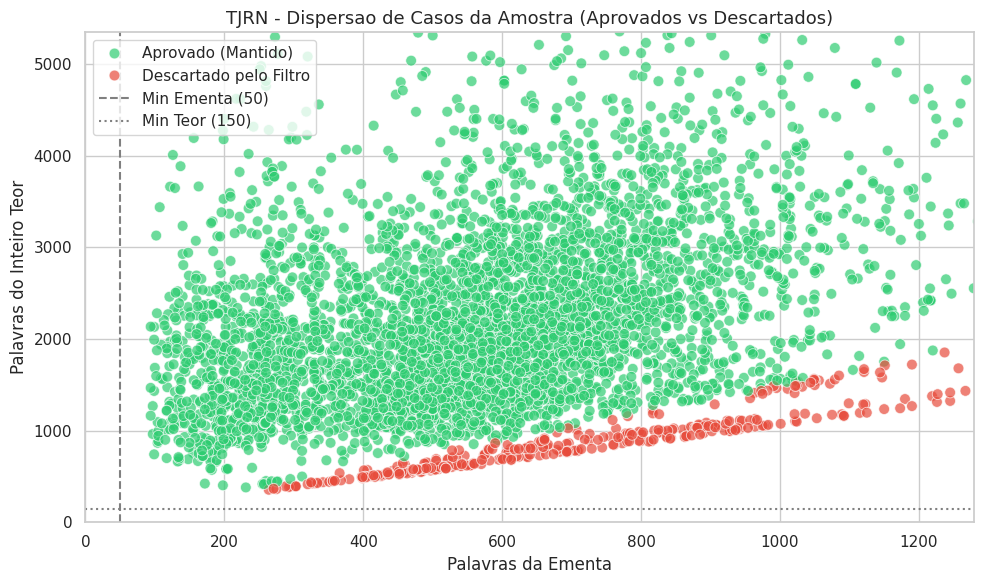

In [8]:
# 1.2 Simulador de Cortes e Grafico de Dispersao (Apoio a Decisao)
# Simula o impacto de diferentes limiares de palavras na taxa de aprovacao

opcoes_ementa = [20, 30, 35, 40, 50]
opcoes_teor = [100, 150, 200, 250, 300]

matriz_retencao = []
for pe in opcoes_ementa:
    linha = {}
    for pt in opcoes_teor:
        passou = (
            (df_diag["palavras_ementa"] >= pe) &
            (df_diag["palavras_teor"] >= pt) &
            (df_diag["palavras_teor"] >= df_diag["palavras_ementa"] * FATOR_TEOR_EMENTA)
        ).mean() * 100.0
        linha[f"Teor >= {pt}"] = f"{passou:.1f}%"
    matriz_retencao.append(linha)

df_simulador = pd.DataFrame(matriz_retencao, index=[f"Ementa >= {pe}" for pe in opcoes_ementa])
print("SIMULADOR DE TAXA DE RETENCAO (%) PARA DIFERENTES CORTES:")
display(df_simulador)

# Grafico de Dispersao (Scatter Plot): Ementa vs Teor com status de aprovacao
status_aprovado = (
    (df_diag["palavras_ementa"] >= MIN_PALAVRAS_EMENTA) &
    (df_diag["palavras_teor"] >= MIN_PALAVRAS_TEOR) &
    (df_diag["palavras_teor"] >= df_diag["palavras_ementa"] * FATOR_TEOR_EMENTA)
)
df_diag["status"] = np.where(status_aprovado, "Aprovado (Mantido)", "Descartado pelo Filtro")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_diag,
    x="palavras_ementa",
    y="palavras_teor",
    hue="status",
    palette={"Aprovado (Mantido)": "#2ecc71", "Descartado pelo Filtro": "#e74c3c"},
    alpha=0.7,
    s=60
)

# Linhas de corte configuradas
plt.axvline(MIN_PALAVRAS_EMENTA, color="gray", linestyle="--", label=f"Min Ementa ({MIN_PALAVRAS_EMENTA})")
plt.axhline(MIN_PALAVRAS_TEOR, color="gray", linestyle=":", label=f"Min Teor ({MIN_PALAVRAS_TEOR})")

plt.title(f"{SIGLA_TRIBUNAL} - Dispersao de Casos da Amostra (Aprovados vs Descartados)", fontsize=13)
plt.xlabel("Palavras da Ementa")
plt.ylabel("Palavras do Inteiro Teor")
plt.xlim(0, df_diag["palavras_ementa"].quantile(0.98) * 1.1)
plt.ylim(0, df_diag["palavras_teor"].quantile(0.98) * 1.1)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [9]:
# 1.3 Visualizador HTML de Registros Completos
INDICE_VISUALIZAR = 2 #@param {type:"integer"}

def fmt_meta(rec: dict, chave: str) -> str:
    val = rec.get(chave)
    if isinstance(val, dict):
        return str(val.get("nome") or val.get("descricao") or val)
    return str(val or "")

def mostrar_registro(rec: dict, rotulo: str, recorte: int = 1200):
    eme = limpar_texto(pegar_ementa(rec, COLUNA_EMENTA_CUSTOM))
    teo = limpar_texto(pegar_teor(rec, COLUNA_TEOR_CUSTOM))
    num = pegar_numero(rec, COLUNA_NUMERO_CUSTOM)

    extra = {
        "relator": fmt_meta(rec, "relator") or fmt_meta(rec, "nomeRelator"),
        "orgaoJulgador": fmt_meta(rec, "orgaoJulgador") or fmt_meta(rec, "orgao_julgador") or fmt_meta(rec, "orgao_judicante"),
        "classe": fmt_meta(rec, "classe") or fmt_meta(rec, "classe_judicial") or fmt_meta(rec, "tipo_documento"),
        "data": fmt_meta(rec, "dataJulgamento") or fmt_meta(rec, "data_julgamento") or fmt_meta(rec, "data_publicacao")
    }

    meta_html = "".join(
        f"<div><b>{html.escape(k)}</b>: {html.escape(v)}</div>"
        for k, v in extra.items() if v
    )

    card_html = (
        "<div style='border:1px solid #ccc;padding:16px;margin:12px 0;border-radius:8px;font-family:sans-serif'>"
        f"<div style='background:#1f4e79;color:#fff;padding:8px 12px;border-radius:5px'>"
        f"<b>{html.escape(rotulo)}</b> | Processo: {html.escape(num)}"
        "</div>"
        f"<div style='margin:12px 0;font-size:0.95em;color:#333'>{meta_html}</div>"
        f"<h4 style='color:#1f4e79;margin-bottom:4px'>Ementa ({len(eme):,} caracteres | {len(eme.split())} palavras)</h4>"
        f"<pre style='white-space:pre-wrap;max-height:220px;overflow:auto;background:#f7f7f7;border:1px solid #e0e0e0;padding:12px;border-radius:4px'>"
        f"{html.escape(eme[:recorte] or '(VAZIO)')}</pre>"
        f"<h4 style='color:#1f4e79;margin-bottom:4px'>Inteiro Teor ({len(teo):,} caracteres | {len(teo.split())} palavras)</h4>"
        f"<pre style='white-space:pre-wrap;max-height:340px;overflow:auto;background:#f7f7f7;border:1px solid #e0e0e0;padding:12px;border-radius:4px'>"
        f"{html.escape(teo[:recorte] or '(VAZIO)')}</pre>"
        "</div>"
    )
    display(HTML(card_html))

idx = INDICE_VISUALIZAR % len(amostra_exploracao)
mostrar_registro(amostra_exploracao[idx], f"{SIGLA_TRIBUNAL} - Registro [{idx}]", RECORTE_VISUALIZADOR)


## PARTE 2: Geracao dos Pares em Passada Unica

Executa a gravacao direta dos pares aprovados no formato do BumbaLM, aplicando a limpeza e os filtros de qualidade configurados.

In [ ]:
# 2.0 Extrair e Gravar Pares em Passada Unica (.jsonl)
nome_arquivo_saida = f"pares_{SIGLA_TRIBUNAL.lower()}.jsonl"
caminho_saida = Path(PASTA_SAIDA) / nome_arquivo_saida

print("=" * 84)
print(f"INICIANDO EXTRACAO: {SIGLA_TRIBUNAL}")
print(f"Origem   : {caminho_entrada}")
print(f"Destino  : {caminho_saida}")
print(f"Filtros  : Ementa >= {MIN_PALAVRAS_EMENTA} palavras | Teor >= {MIN_PALAVRAS_TEOR} palavras | Razao >= {FATOR_TEOR_EMENTA}x")
print(f"Limite   : {MAX_PARES if MAX_PARES > 0 else 'Arquivo Completo'}")
print("=" * 84)

motivos = Counter()
total_lidos = 0
total_salvos = 0
vistos = set()
limite_loop = None if MAX_PARES <= 0 else MAX_PARES
t0 = time.time()

with open(caminho_saida, "w", encoding="utf-8") as fout:
    pbar = tqdm(iterar_registros(caminho_entrada), desc=f"Pares {SIGLA_TRIBUNAL}", unit=" docs")
    for rec in pbar:
        if not isinstance(rec, dict):
            continue
        total_lidos += 1

        numero = pegar_numero(rec, COLUNA_NUMERO_CUSTOM)
        id_reg = pegar_id(rec)

        identificador = numero or id_reg
        digitos = NUMERO_RE.sub("", identificador)

        if not identificador or (digitos and set(digitos) <= {"0"}):
            motivos["numero_dummy_ou_vazio"] += 1
            continue

        eme_bruta = pegar_ementa(rec, COLUNA_EMENTA_CUSTOM)
        teo_bruta = pegar_teor(rec, COLUNA_TEOR_CUSTOM)

        if not eme_bruta or not teo_bruta:
            motivos["campo_vazio"] += 1
            continue

        ementa = limpar_texto(eme_bruta)
        teor = limpar_texto(teo_bruta)

        palavras_eme = len(ementa.split())
        palavras_teo = len(teor.split())

        if palavras_eme < MIN_PALAVRAS_EMENTA:
            motivos["ementa_curta"] += 1
            continue
        if palavras_teo < MIN_PALAVRAS_TEOR:
            motivos["teor_curto"] += 1
            continue
        if palavras_teo < (palavras_eme * FATOR_TEOR_EMENTA):
            motivos["teor_parecido_ementa"] += 1
            continue

        if not eh_texto_valido(ementa):
            motivos["ementa_corrompida_ocr_pdf"] += 1
            continue
        if not eh_texto_valido(teor):
            motivos["teor_corrompido_ocr_pdf"] += 1
            continue
        chave = f"{numero}#{id_reg}" if (id_reg and numero and numero != id_reg) else identificador
        chave_norm = re.sub(r"[^\w]+", "", chave)
        if not chave_norm or chave_norm in vistos:
            motivos["id_duplicado"] += 1
            continue

        par_registro = {
            "str_tribunal": SIGLA_TRIBUNAL,
            "str_numero_unico": chave,
            "str_ementa": ementa,
            "str_inteiro_teor": teor
        }

        fout.write(json.dumps(par_registro, ensure_ascii=False) + "\n")
        vistos.add(chave_norm)
        total_salvos += 1

        if limite_loop and total_salvos >= limite_loop:
            break

tempo_total = time.time() - t0
tam_in_mb = caminho_entrada.stat().st_size / 1e6
tam_out_mb = caminho_saida.stat().st_size / 1e6
reducao_pct = (1.0 - (tam_out_mb / tam_in_mb)) * 100.0 if tam_in_mb > 0 else 0

print("\n" + "=" * 84)
print(f"RESULTADO DA EXTRACAO: {SIGLA_TRIBUNAL}")
print(f"  - Total Processado     : {total_lidos:,}")
print(f"  - Total Salvo (Validos): {total_salvos:,} ({total_salvos / max(1, total_lidos):.1%})")
print(f"  - Tamanho Original     : {tam_in_mb:.1f} MB")
print(f"  - Tamanho Final        : {tam_out_mb:.1f} MB ({reducao_pct:.1f}% de reducao)")
print(f"  - Tempo de Execucao    : {tempo_total:.1f}s ({total_lidos / max(0.1, tempo_total):.0f} reg/s)")
print(f"  - Arquivo Salvo        : {caminho_saida}")
print("=" * 84)

# Grafico de Barras dos Motivos de Descarte
if motivos:
    df_motivos = pd.DataFrame(list(motivos.items()), columns=["Motivo", "Quantidade"]).sort_values("Quantidade", ascending=True)
    plt.figure(figsize=(10, 4))
    plt.barh(df_motivos["Motivo"], df_motivos["Quantidade"], color="#e67e22")
    plt.title(f"{SIGLA_TRIBUNAL} - Distribuicao dos Motivos de Descarte", fontsize=12)
    plt.xlabel("Quantidade de Registros Descartados")
    for i, v in enumerate(df_motivos["Quantidade"]):
        plt.text(v + (max(df_motivos["Quantidade"]) * 0.01), i, f"{v:,}", va="center", fontsize=10)
    plt.tight_layout()
    plt.show()


INICIANDO EXTRACAO: TJRN
Origem   : /content/drive/MyDrive/Raspagem_Dados/TJRN/rn_consolidado.jsonl
Destino  : /content/drive/MyDrive/Pares_Tribunais/pares_tjrn.jsonl
Filtros  : Ementa >= 50 palavras | Teor >= 150 palavras | Razao >= 1.5x
Limite   : Arquivo Completo


Pares TJRN: 0 docs [00:00, ? docs/s]

In [ ]:
# 2.1 Amostras Visuais dos Pares Gerados no Arquivo Final
N_AMOSTRAS_VISUAL = 3
linhas_amostra = []

with open(caminho_saida, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            linhas_amostra.append(line)
        if len(linhas_amostra) >= 500:
            break

sorteio = random.sample(linhas_amostra, min(N_AMOSTRAS_VISUAL, len(linhas_amostra)))
cards = ""
for i, l in enumerate(sorteio, start=1):
    p = json.loads(l)
    eme_txt = p.get("str_ementa", "")
    teo_txt = p.get("str_inteiro_teor", "")
    cards += (
        "<div style='border:1px solid #ddd;padding:16px;margin:16px 0;border-radius:8px;font-family:sans-serif'>"
        f"<div style='background:#2c3e50;color:#fff;padding:8px 12px;border-radius:5px'>"
        f"<b>Amostra {i}</b> | Tribunal: {p.get('str_tribunal')} | Processo: {p.get('str_numero_unico')}"
        "</div>"
        f"<h4 style='color:#2c3e50;margin-bottom:4px'>Ementa ({len(eme_txt):,} chars | {len(eme_txt.split())} palavras)</h4>"
        f"<pre style='white-space:pre-wrap;max-height:220px;overflow:auto;background:#fcfcfc;border:1px solid #eee;padding:12px;border-radius:4px'>{html.escape(eme_txt)}</pre>"
        f"<h4 style='color:#2c3e50;margin-bottom:4px'>Inteiro Teor ({len(teo_txt):,} chars | {len(teo_txt.split())} palavras)</h4>"
        f"<pre style='white-space:pre-wrap;max-height:320px;overflow:auto;background:#fcfcfc;border:1px solid #eee;padding:12px;border-radius:4px'>{html.escape(teo_txt[:3000])}</pre>"
        "</div>"
    )
display(HTML(cards))

In [ ]:
# 2.2 Metricas Finais e Histogramas de Palavras dos Pares Salvos
stats_list = []

with open(caminho_saida, "r", encoding="utf-8") as f:
    for line in tqdm(f, desc="Coletando metricas", unit=" pares"):
        if not line.strip():
            continue
        doc = json.loads(line)
        e = doc.get("str_ementa", "")
        t = doc.get("str_inteiro_teor", "")
        stats_list.append({
            "palavras_ementa": len(e.split()),
            "palavras_teor": len(t.split()),
            "chars_ementa": len(e),
            "chars_teor": len(t)
        })

df_stats = pd.DataFrame(stats_list)
print(f"\nTotal de Pares Validados: {len(df_stats):,}")
display(df_stats.describe().round(1))

# Histogramas com corte nos percentis
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df_stats["palavras_ementa"], bins=50, color="#2980b9", kde=True, ax=axes[0])
axes[0].set_title(f"{SIGLA_TRIBUNAL} - Distribuicao de Palavras da Ementa")
axes[0].set_xlabel("Palavras")
axes[0].set_xlim(0, df_stats["palavras_ementa"].quantile(0.99))

sns.histplot(df_stats["palavras_teor"], bins=50, color="#27ae60", kde=True, ax=axes[1])
axes[1].set_title(f"{SIGLA_TRIBUNAL} - Distribuicao de Palavras do Inteiro Teor")
axes[1].set_xlabel("Palavras")
axes[1].set_xlim(0, df_stats["palavras_teor"].quantile(0.95))

plt.tight_layout()
plt.show()